# Práctica: Modelos Transformers en NLP

Esta práctica usa la librería `transformers` de Hugging Face para probar tres arquitecturas del paper *Attention Is All You Need*:

| Tipo | Modelo | Tarea |
|---|---|---|
| Solo encoder | BERT / BERT multilingüe | Clasificación de sentimiento, relleno de máscara |
| Encoder-decoder | MarianMT | Traducción inglés → español |
| Solo decoder | GPT-2 | Generación de texto |

Al final se visualizan los **pesos de atención** de BERT.

**Instrucciones:** Entorno de ejecución > Cambiar tipo > GPU (opcional). Luego ejecuta todas las celdas en orden (Ctrl+F9) y copia la salida de la última celda.

In [ ]:
!pip -q install transformers torch matplotlib sentencepiece

In [ ]:
import time
import torch
import transformers
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print('transformers:', transformers.__version__)
print('GPU disponible:', torch.cuda.is_available())

resultados = {}  # aquí guardamos todo para el resumen final

transformers: 5.22.1
GPU disponible: False


## 1. Análisis de sentimiento (encoder: BERT multilingüe)
El modelo devuelve de 1 a 5 estrellas.

In [ ]:
textos = [
    'I love how fast this model learns!',
    'Este curso me pareció aburrido y confuso.',
    'La práctica de Transformers estuvo excelente.'
]

clf = pipeline('sentiment-analysis',
               model='nlptown/bert-base-multilingual-uncased-sentiment',
               device=device)
t0 = time.time()
res = clf(textos)
t = time.time() - t0

resultados['sentimiento'] = []
for texto, r in zip(textos, res):
    print(texto)
    print('   ->', r['label'], '| confianza:', round(r['score'], 2))
    resultados['sentimiento'].append((texto, r['label'], round(r['score'], 2)))
print('Tiempo (s):', round(t, 2))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

I love how fast this model learns!
   -> 5 stars | confianza: 0.84
Este curso me pareció aburrido y confuso.
   -> 2 stars | confianza: 0.51
La práctica de Transformers estuvo excelente.
   -> 5 stars | confianza: 0.48
Tiempo (s): 3.16


## 2. Relleno de máscara (encoder: BERT)
BERT predice la palabra oculta usando el contexto a ambos lados.

In [ ]:
unmasker = pipeline('fill-mask', model='bert-base-uncased', device=device)

frases = [
    'The Transformer model relies on [MASK] mechanisms.',
    'Paris is the capital of [MASK].'
]

resultados['mascara'] = {}
for frase in frases:
    print(frase)
    preds = unmasker(frase, top_k=5)
    resultados['mascara'][frase] = [(p['token_str'], round(p['score'], 3)) for p in preds]
    for p in preds:
        print('   ', p['token_str'], round(p['score'], 3))
    print()

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


The Transformer model relies on [MASK] mechanisms.
    several 0.387
    two 0.331
    three 0.073
    multiple 0.041
    many 0.033

Paris is the capital of [MASK].
    france 0.951
    algeria 0.012
    morocco 0.003
    reunion 0.003
    haiti 0.003



## 3. Traducción inglés → español (encoder-decoder)
La arquitectura original del paper.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Cargamos el tokenizador y el modelo de traducción directamente
model_name = 'Helsinki-NLP/opus-mt-en-es'
tok_traductor = AutoTokenizer.from_pretrained(model_name)
modelo_traductor = AutoModelForSeq2SeqLM.from_pretrained(model_name)
if device == 0:
    modelo_traductor = modelo_traductor.to('cuda')

oraciones = [
    'Attention is all you need.',
    'The Transformer allows for significantly more parallelization.',
    'The law will never be perfect, but its application should be just.'
]

t0 = time.time()

# Realizamos la traducción de forma manual
resultados['traduccion'] = []
for o in oraciones:
    inputs = tok_traductor(o, return_tensors='pt')
    if device == 0:
        inputs = {k: v.to('cuda') for k, v in inputs.items()}

    with torch.no_grad():
        translated_tokens = modelo_traductor.generate(**inputs)

    traduccion_texto = tok_traductor.batch_decode(translated_tokens, skip_special_tokens=True)[0]
    print('EN:', o)
    print('ES:', traduccion_texto, '\n')
    resultados['traduccion'].append((o, traduccion_texto))

# Guardamos una referencia compatible para el cálculo de parámetros posterior
traductor = type('DummyTraductor', (object,), {'model': modelo_traductor})

t = time.time() - t0
print('Tiempo (s):', round(t, 2))

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

EN: Attention is all you need.
ES: La atención es todo lo que necesitas. 

EN: The Transformer allows for significantly more parallelization.
ES: El transformador permite una paralelización significativamente mayor. 

EN: The law will never be perfect, but its application should be just.
ES: La ley nunca será perfecta, pero su aplicación debería ser justa. 

Tiempo (s): 8.82


## 4. Generación de texto (decoder: GPT-2)
Modelo autorregresivo con atención enmascarada (no ve posiciones futuras).

In [ ]:
from transformers import set_seed
set_seed(42)

generador = pipeline('text-generation', model='gpt2', device=device)
prompt = 'Transformers are neural networks that'

salida = generador(prompt, max_new_tokens=30, do_sample=False)[0]['generated_text']
print(salida)
resultados['generacion'] = (prompt, salida)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Transformers are neural networks that can be used to predict the future.

The researchers used a technique called deep learning to train a neural network to predict the future. The network


## 5. Visualización de la atención (self-attention de BERT)
Usamos una oración parecida a la de las Figuras 4 y 5 del paper para ver a qué palabras atiende `its`.

In [ ]:
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

tok = AutoTokenizer.from_pretrained('bert-base-uncased')
bert = AutoModel.from_pretrained('bert-base-uncased', output_attentions=True)
bert.eval()

frase = 'The law will never be perfect, but its application should be just'
inputs = tok(frase, return_tensors='pt')
with torch.no_grad():
    out = bert(**inputs)

att = out.attentions  # tupla: una entrada por capa, forma (1, cabezas, seq, seq)
tokens = tok.convert_ids_to_tokens(inputs['input_ids'][0])

print('Tokens:', tokens)
print('Capas:', len(att), '| Cabezas por capa:', att[0].shape[1], '| Longitud de secuencia:', att[0].shape[2])

resultados['atencion_forma'] = (len(att), att[0].shape[1], att[0].shape[2])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Tokens: ['[CLS]', 'the', 'law', 'will', 'never', 'be', 'perfect', ',', 'but', 'its', 'application', 'should', 'be', 'just', '[SEP]']
Capas: 12 | Cabezas por capa: 12 | Longitud de secuencia: 15


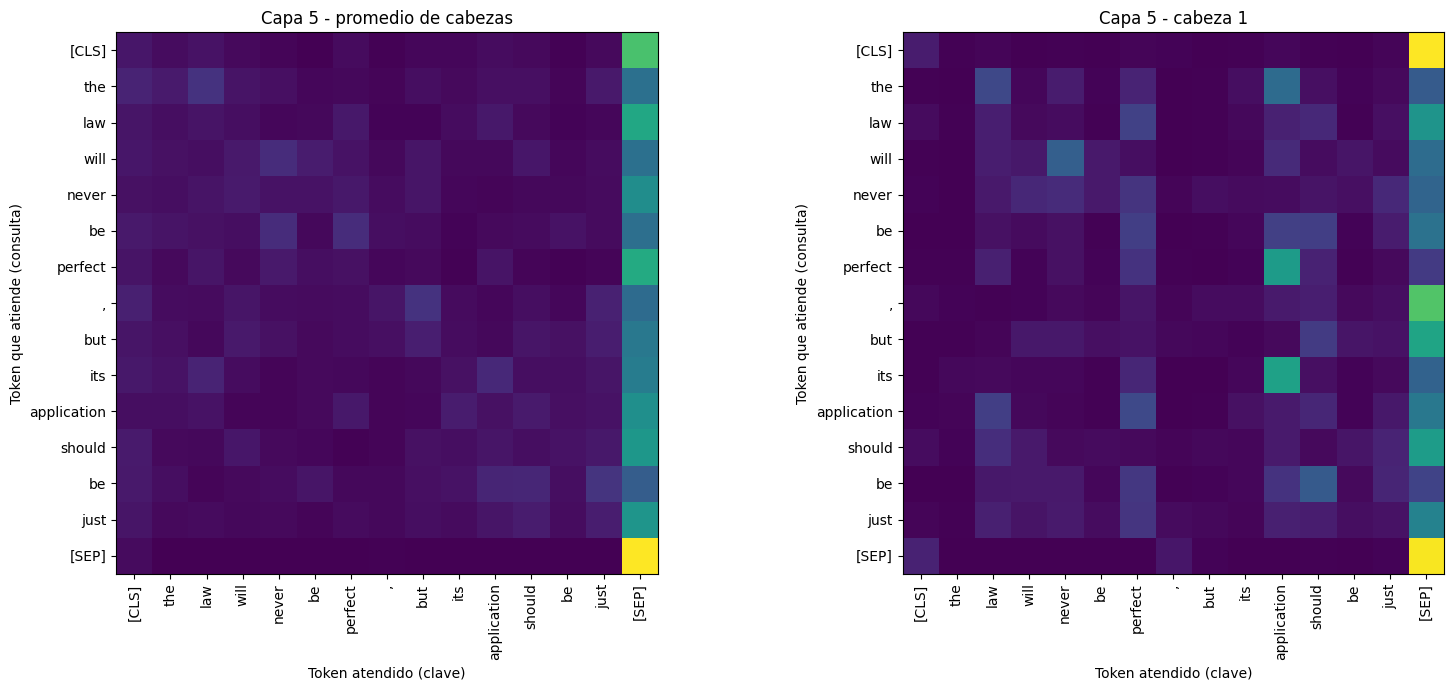

In [ ]:
capa = 4  # capa 5 (índice 4), igual que las figuras del paper
promedio = att[capa][0].mean(dim=0).numpy()  # promedio de las cabezas

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, matriz, titulo in zip(axes,
                              [promedio, att[capa][0][0].numpy()],
                              ['Capa 5 - promedio de cabezas', 'Capa 5 - cabeza 1']):
    ax.imshow(matriz, cmap='viridis')
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticklabels(tokens)
    ax.set_title(titulo)
    ax.set_xlabel('Token atendido (clave)')
    ax.set_ylabel('Token que atiende (consulta)')
plt.tight_layout()
plt.savefig('atencion_bert.png', dpi=150)
plt.show()

In [ ]:
# ¿A qué token atiende más 'its' en cada cabeza de la capa 5?
idx = tokens.index('its')
resultados['its_por_cabeza'] = []
for h in range(att[capa].shape[1]):
    pesos = att[capa][0][h][idx]
    j = int(pesos.argmax())
    print('Cabeza', h + 1, '->', tokens[j], '| peso:', round(float(pesos[j]), 2))
    resultados['its_por_cabeza'].append((h + 1, tokens[j], round(float(pesos[j]), 2)))

Cabeza 1 -> application | peso: 0.48
Cabeza 2 -> just | peso: 0.2
Cabeza 3 -> [SEP] | peso: 0.6
Cabeza 4 -> [SEP] | peso: 0.38
Cabeza 5 -> will | peso: 0.19
Cabeza 6 -> application | peso: 0.31
Cabeza 7 -> [SEP] | peso: 0.32
Cabeza 8 -> [SEP] | peso: 0.87
Cabeza 9 -> [SEP] | peso: 0.6
Cabeza 10 -> [SEP] | peso: 0.36
Cabeza 11 -> law | peso: 0.8
Cabeza 12 -> [SEP] | peso: 0.52


## 6. Tamaño de los modelos

In [ ]:
def millones(m):
    return round(sum(p.numel() for p in m.parameters()) / 1e6, 1)

resultados['parametros_millones'] = {
    'BERT multilingue (sentimiento)': millones(clf.model),
    'BERT base (mascara)': millones(unmasker.model),
    'MarianMT en-es (traduccion)': millones(traductor.model),
    'GPT-2 (generacion)': millones(generador.model),
}
for k, v in resultados['parametros_millones'].items():
    print(k, ':', v, 'M parámetros')

BERT multilingue (sentimiento) : 167.4 M parámetros
BERT base (mascara) : 109.5 M parámetros
MarianMT en-es (traduccion) : 77.9 M parámetros
GPT-2 (generacion) : 124.4 M parámetros
